In [1]:
# House Price Prediction
# Alfido Tech Machine Learning Internship
# Task 2

print("House Price Prediction Project")

House Price Prediction Project


In [2]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
# Load the dataset

df = pd.read_csv('/content/data[1].csv')

# Display first five rows
print(df.head())

                  date      price  bedrooms  bathrooms  sqft_living  sqft_lot  \
0  2014-05-02 00:00:00   313000.0       3.0       1.50         1340      7912   
1  2014-05-02 00:00:00  2384000.0       5.0       2.50         3650      9050   
2  2014-05-02 00:00:00   342000.0       3.0       2.00         1930     11947   
3  2014-05-02 00:00:00   420000.0       3.0       2.25         2000      8030   
4  2014-05-02 00:00:00   550000.0       4.0       2.50         1940     10500   

   floors  waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0     1.5           0     0          3        1340              0      1955   
1     2.0           0     4          5        3370            280      1921   
2     1.0           0     0          4        1930              0      1966   
3     1.0           0     0          4        1000           1000      1963   
4     1.0           0     0          4        1140            800      1976   

   yr_renovated                    str

In [5]:
# Dataset information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (4600, 18)

Column Names:
Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           4600 non-null   object 
 1   price          4600 non-null   float64
 2   bedrooms       4600 non-null   float64
 3   bathrooms      4600 non-null   float64
 4   sqft_living    4600 non-null   int64  
 5   sqft_lot       4600 non-null   int64  
 6   floors         4600 non-null   float64
 7   waterfront     4600 non-null   int64  
 8   view           4600 non-null   int64  
 9   condition      4600 non-null   int64  
 10  sqft_above     4600 non-null   i

In [6]:
# Basic statistical analysis

print("Dataset Shape:", df.shape)

print("\nStatistical Summary:")
print(df.describe())

print("\nDataset Columns:")
print(df.columns.tolist())

Dataset Shape: (4600, 18)

Statistical Summary:
              price     bedrooms    bathrooms   sqft_living      sqft_lot  \
count  4.600000e+03  4600.000000  4600.000000   4600.000000  4.600000e+03   
mean   5.519630e+05     3.400870     2.160815   2139.346957  1.485252e+04   
std    5.638347e+05     0.908848     0.783781    963.206916  3.588444e+04   
min    0.000000e+00     0.000000     0.000000    370.000000  6.380000e+02   
25%    3.228750e+05     3.000000     1.750000   1460.000000  5.000750e+03   
50%    4.609435e+05     3.000000     2.250000   1980.000000  7.683000e+03   
75%    6.549625e+05     4.000000     2.500000   2620.000000  1.100125e+04   
max    2.659000e+07     9.000000     8.000000  13540.000000  1.074218e+06   

            floors   waterfront         view    condition   sqft_above  \
count  4600.000000  4600.000000  4600.000000  4600.000000  4600.000000   
mean      1.512065     0.007174     0.240652     3.451739  1827.265435   
std       0.538288     0.084404     

In [7]:
# Check missing values

print(df.isnull().sum())

print("\nTotal Missing Values:",
      df.isnull().sum().sum())

date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
street           0
city             0
statezip         0
country          0
dtype: int64

Total Missing Values: 0


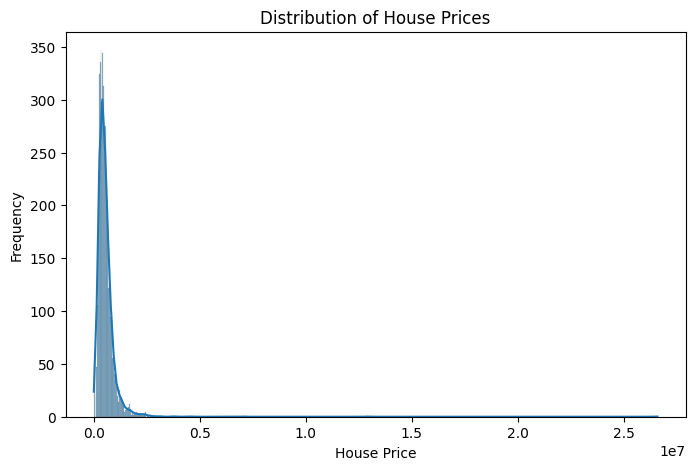

In [8]:
# Distribution of house prices

plt.figure(figsize=(8, 5))

sns.histplot(df['price'], kde=True)

plt.title("Distribution of House Prices")
plt.xlabel("House Price")
plt.ylabel("Frequency")

plt.show()

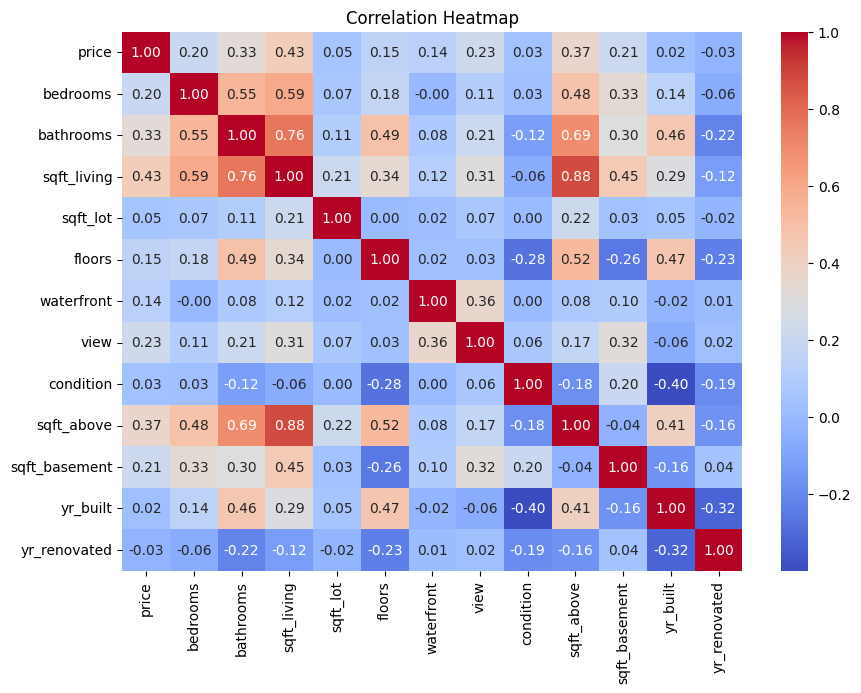

In [9]:
# Correlation analysis

numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 7))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.show()

Index(['date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot',
       'floors', 'waterfront', 'view', 'condition', 'sqft_above',
       'sqft_basement', 'yr_built', 'yr_renovated', 'street', 'city',
       'statezip', 'country'],
      dtype='object')


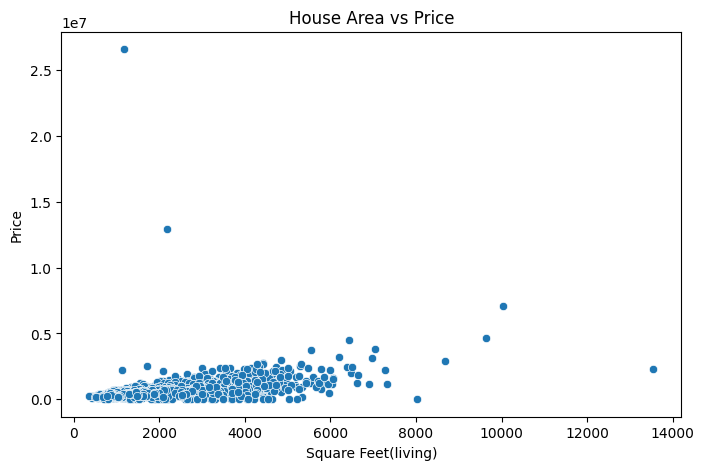

In [15]:
# Area vs Price
print(df.columns)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='sqft_living',
    y='price'
)

plt.title("House Area vs Price")
plt.xlabel("Square Feet(living)")
plt.ylabel("Price")

plt.show()

In [16]:
# Separate features and target

X = df.drop('price', axis=1)
y = df['price']

print("Input Features:")
print(X.head())

print("\nTarget Variable:")
print(y.head())

Input Features:
                  date  bedrooms  bathrooms  sqft_living  sqft_lot  floors  \
0  2014-05-02 00:00:00       3.0       1.50         1340      7912     1.5   
1  2014-05-02 00:00:00       5.0       2.50         3650      9050     2.0   
2  2014-05-02 00:00:00       3.0       2.00         1930     11947     1.0   
3  2014-05-02 00:00:00       3.0       2.25         2000      8030     1.0   
4  2014-05-02 00:00:00       4.0       2.50         1940     10500     1.0   

   waterfront  view  condition  sqft_above  sqft_basement  yr_built  \
0           0     0          3        1340              0      1955   
1           0     4          5        3370            280      1921   
2           0     0          4        1930              0      1966   
3           0     0          4        1000           1000      1963   
4           0     0          4        1140            800      1976   

   yr_renovated                    street       city  statezip country  
0          2005

In [17]:
# Convert categorical variables using One-Hot Encoding

X = pd.get_dummies(X, drop_first=True)

print("Encoded Dataset:")
print(X.head())

print("\nTotal Features:", X.shape[1])

Encoded Dataset:
   bedrooms  bathrooms  sqft_living  sqft_lot  floors  waterfront  view  \
0       3.0       1.50         1340      7912     1.5           0     0   
1       5.0       2.50         3650      9050     2.0           0     4   
2       3.0       2.00         1930     11947     1.0           0     0   
3       3.0       2.25         2000      8030     1.0           0     0   
4       4.0       2.50         1940     10500     1.0           0     0   

   condition  sqft_above  sqft_basement  ...  statezip_WA 98155  \
0          3        1340              0  ...              False   
1          5        3370            280  ...              False   
2          4        1930              0  ...              False   
3          4        1000           1000  ...              False   
4          4        1140            800  ...              False   

   statezip_WA 98166  statezip_WA 98168  statezip_WA 98177  statezip_WA 98178  \
0              False              False         

In [18]:
# Handle missing values

imputer = SimpleImputer(strategy='median')

X = pd.DataFrame(
    imputer.fit_transform(X),
    columns=X.columns
)

print("Missing values handled successfully!")
print(X.isnull().sum().sum())

Missing values handled successfully!
0


In [19]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (3680, 4724)
Testing Data: (920, 4724)


In [20]:
# Apply Standard Scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

Feature scaling completed successfully!


from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

print("Models imported successfully!")

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

print("Models imported successfully!")

Models imported successfully!


In [22]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

lr_predictions = lr_model.predict(X_test_scaled)

print("Linear Regression Training Completed!")

Linear Regression Training Completed!


In [23]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest Training Completed!")

Random Forest Training Completed!


In [24]:
gb_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

gb_model.fit(X_train, y_train)

gb_predictions = gb_model.predict(X_test)

print("Gradient Boosting Training Completed!")

Gradient Boosting Training Completed!


In [25]:
print("Actual House Prices:")
print(y_test.head())

print("\nLinear Regression Predictions:")
print(lr_predictions[:5])

print("\nRandom Forest Predictions:")
print(rf_predictions[:5])

print("\nGradient Boosting Predictions:")
print(gb_predictions[:5])

Actual House Prices:
3683     544000.0
4411          0.0
2584    1712500.0
69       365000.0
1844     275000.0
Name: price, dtype: float64

Linear Regression Predictions:
[ 493187.75924953  278172.67717967 1224003.00740934  251452.62725471
  474308.67773997]

Random Forest Predictions:
[ 443871.76        324425.20369046 1174294.175       359303.625
  238389.76238095]

Gradient Boosting Predictions:
[ 429992.04541926  381965.43949971 1075567.82851141  419088.09727074
  285914.3355147 ]


In [26]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import numpy as np

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [27]:
# Calculate evaluation metrics

models = {
    "Linear Regression": lr_predictions,
    "Random Forest": rf_predictions,
    "Gradient Boosting": gb_predictions
}

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    print("\nModel:", name)
    print("MAE:", mae)
    print("RMSE:", rmse)
    print("R2 Score:", r2)


Model: Linear Regression
MAE: 262113.66199590702
RMSE: 1070924.3613021902
R2 Score: -0.12456057599100467

Model: Random Forest
MAE: 157066.07315951728
RMSE: 985101.2940099346
R2 Score: 0.04846002646113656

Model: Gradient Boosting
MAE: 163062.3237046071
RMSE: 982326.0881841424
R2 Score: 0.05381378978632789


               Model            MAE          RMSE  R2 Score
0  Linear Regression  262113.661996  1.070924e+06 -0.124561
1      Random Forest  157066.073160  9.851013e+05  0.048460
2  Gradient Boosting  163062.323705  9.823261e+05  0.053814


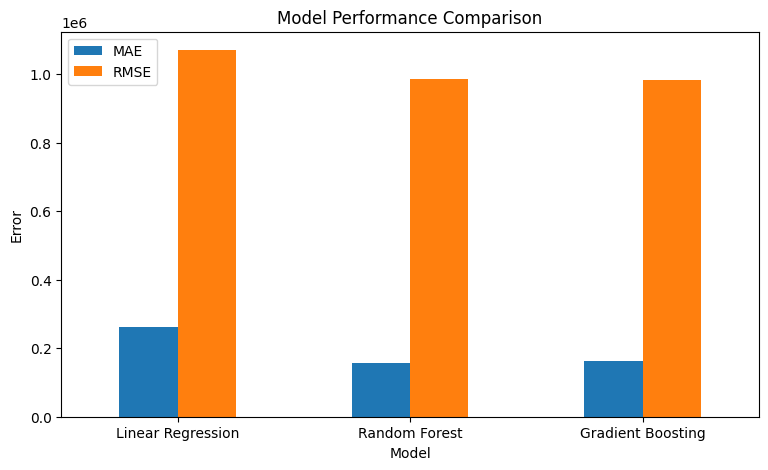

In [28]:
# Compare model performance

results = []

for name, predictions in models.items():

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2 Score": r2_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

print(results_df)

results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)
plt.show()

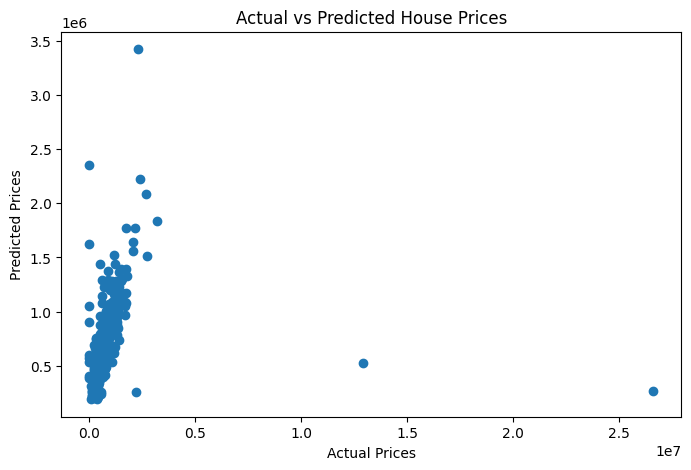

In [29]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, gb_predictions)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")

plt.title("Actual vs Predicted House Prices")

plt.show()

In [30]:
# Select the best model based on RMSE

best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(), "Model"
]

print("Best Model:", best_model_name)

if best_model_name == "Linear Regression":
    best_model = lr_model
elif best_model_name == "Random Forest":
    best_model = rf_model
else:
    best_model = gb_model

print("Best model selected successfully!")

Best Model: Gradient Boosting
Best model selected successfully!


In [31]:
import joblib

# Save the best model

joblib.dump(best_model, "best_house_price_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [32]:
joblib.dump(scaler, "scaler.pkl")

joblib.dump(imputer, "imputer.pkl")

print("Scaler and Imputer saved successfully!")

Scaler and Imputer saved successfully!


In [33]:
# Load saved model

loaded_model = joblib.load("best_house_price_model.pkl")

print("Model loaded successfully!")

Model loaded successfully!


In [34]:
from google.colab import files

files.download("best_house_price_model.pkl")
files.download("scaler.pkl")
files.download("imputer.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# Test prediction using the selected best model

if best_model_name == "Linear Regression":
    sample_input = X_test_scaled[:1]
else:
    sample_input = X_test.iloc[:1]

predicted_price = best_model.predict(sample_input)

print("Predicted House Price:", predicted_price[0])
print("Actual House Price:", y_test.iloc[0])

Predicted House Price: 429992.04541925684
Actual House Price: 544000.0


In [36]:
# Save evaluation results

results_df.to_csv("model_comparison.csv", index=False)

print("Model comparison saved successfully!")

Model comparison saved successfully!
